In [2]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib
import numpy as np
import matplotlib.pyplot as plt
import joblib
import anndata as ad
from scipy.signal import find_peaks
import h5py
import sys
from pathlib import Path


sys_type = sys.platform

SET_JPARAM = False # Set the parameter values for the simulation using PSO-optimized values
PSO_NUM = 2

SAVE_DIR = Path(Path.home(),'ECM_mod_output')
SAVE_DIR.mkdir(exist_ok=True)

SAVEFILES = True
OVERWRITE = True

In [3]:
# Important params to set the window size and step time distance
init_dt = 0.1                 # initial dt from the raw model output
dt = 0.1                      # dt for umap window
window = 4                    # window size in hours
time_step = 0.5               # time step between windows

#umap params
neighbs = 100
min_d = 0.1

# set the random state for reproducibility; set to None to get different results each time
RANDOM_STATE = 10

In [4]:
if sys_type == 'darwin':
    sys_name = 'mac'
    r_path_date = '20240730'
    r_dbpath = 'https://www.dropbox.com/scl/fi/pvx434xg8e391bil5b8wd/reducer_mac_0.1_0.1_4_0.5.sav?rlkey=nuwm98ld3guyukz14a9m6ewu7&dl=1'
if sys_type == 'win32':
    sys_name = 'win'
    r_path_date = '20240301'
    r_dbpath = 'https://www.dropbox.com/s/a0jo15tvh70wrjv/reducer_win_0.1_0.1_4_0.5.sav?dl=1'
if sys_type == 'linux':
    sys_name = 'linux'
    r_path_date = '20240606'
    r_dbpath = "https://www.dropbox.com/scl/fi/79lp5174wny1ngiy4w1h7/reducer_20240606_0.1_0.1_4_0.5.sav?rlkey=3p1xkbzkdmwy9ivmn5r64xtlh&dl=1"

if SET_JPARAM:
    r_name = f'reducerPSO_{PSO_NUM}_{sys_name}_{init_dt}_{dt}_{window}_{time_step}_{neighbs}_{min_d}.sav'
else:
    r_name = f'reducer_{sys_name}_{init_dt}_{dt}_{window}_{time_step}_{neighbs}_{min_d}.sav'

In [5]:
prot = joblib.load(Path(SAVE_DIR, f'all_prot_stoch_conds_{sys_name}_orig.sav'))
umap_embed = joblib.load(Path(SAVE_DIR, f'all_embedding_stoch_conds_{sys_name}_orig.sav')) # corresponding UMAP embedded data
prot_d = joblib.load(SAVE_DIR / f'all_prot_stoch_cdk46i_{sys_name}.sav')  # windowed data
umap_d_embed = joblib.load(SAVE_DIR / f'all_embedding_stoch_cdk46i_{sys_name}.sav') # corresponding UMAP embedded data


### Load data from 07_cellxgene_prep

In [6]:
adata = ad.read_h5ad(Path(SAVE_DIR,'orig_params_0603-wELong.h5ad'))

In [7]:
adata.obs.columns

Index(['drug', 'stiffness', 'G1_time'], dtype='object')

In [8]:
def getIMT(prot):
    peaks_E, _ = find_peaks(prot[:,int((win_len*11+win_len/2)-1)], prominence = 40/200, distance = 10)
    peaks_cdc, _ = find_peaks(prot[:,int((win_len*17+win_len/2)-1)], prominence = 40/200, distance = 10)
    
    time_st = 0.1

    #Padding for beginning of run
    tmp = np.empty((peaks_E[3],1))
    tmp[:] = np.nan
    tmp_ind = tmp
    div_time = pd.DataFrame(tmp)

    div_inds = pd.DataFrame(tmp)
    div_phase = pd.DataFrame(tmp)
    ii=0
    
    for n in range(3,len(peaks_E)-3):   #make sure we have divisions at ends 
        tmp_g1_s = peaks_E[n]
        tmp_g1_s_2 = peaks_E[n+1]
        tmp_g1_s_3 = peaks_E[n+2]  
        
        tmp_mit = peaks_cdc[(tmp_g1_s < peaks_cdc) & (peaks_cdc < tmp_g1_s_2)]
        tmp_mit2 = peaks_cdc[(tmp_g1_s_2 < peaks_cdc) & (peaks_cdc < tmp_g1_s_3)]
          
             
        if (np.size(tmp_mit) > 0) & (np.size(tmp_mit2)>0):
            ordered = [tmp_g1_s, tmp_mit[0], tmp_g1_s_2, tmp_mit2[0], tmp_g1_s_3]
            g1_len_tmp = np.array([ordered[2]*time_st]) - np.array([ordered[1]*time_st])
            tmp = [g1_len_tmp]*int(ordered[2]-ordered[0])
            tmp_ind = [np.array([ii])]*int(ordered[2]-ordered[0])
            tmp_g1 = ['G1']*int(ordered[2]-ordered[1])
            tmp_s_m = ['S-G2-M']*int(ordered[1]-ordered[0])
            tmp = np.concatenate(tmp, axis=0)
            tmp_ind = np.concatenate(tmp_ind, axis=0)

            tmp_df = pd.DataFrame(tmp)
            tmp_df_ind = pd.DataFrame(tmp_ind)
            tmp_g1_df = pd.DataFrame(tmp_g1)
            tmp_s_m_df = pd.DataFrame(tmp_s_m)            

            div_time = pd.concat([div_time, tmp_df], ignore_index=True)
            div_inds = pd.concat([div_inds, tmp_df_ind], ignore_index=True)
            div_phase = pd.concat([div_phase, tmp_s_m_df], ignore_index=True)
            div_phase = pd.concat([div_phase, tmp_g1_df], ignore_index=True)
            
            ii+=1
        else:
            tmp = np.empty((int(peaks_E[n+1]-peaks_E[n]),1))
            tmp[:] = np.nan
            tmp_df = pd.DataFrame(tmp)
            div_time = pd.concat([div_time, tmp_df], ignore_index=True) 
            div_inds = pd.concat([div_inds, tmp_df], ignore_index=True)
            div_phase = pd.concat([div_phase, tmp_df], ignore_index=True)

            ii+=1

    # Padding for end of run
    tmp = np.empty((len(prot)-peaks_E[-3],1))
    tmp[:] = np.nan
    tmp_df = pd.DataFrame(tmp)
    div_time = pd.concat([div_time, tmp_df], ignore_index=True) 
    div_inds = pd.concat([div_inds, tmp_df], ignore_index=True)
    div_phase = pd.concat([div_phase, tmp_df], ignore_index=True)
    
    return div_time, div_inds, div_phase

In [7]:
# tmp_g1 = ['G1']*int(5)
# tmp_g1_df = pd.DataFrame(tmp_g1)
# tmp_g1_df

In [9]:
len_prot = int(prot.shape[0]/10)
win_len = int(prot.shape[1]/18)

In [10]:
all_divs = []
all_div_inds = []
all_phase = []
for num in range(10):
    tmp_div, div_inds, div_phase = getIMT(prot[num*len_prot:(num+1)*len_prot,:])
    tmp_list = tmp_div[0].values.tolist()
    tmp_ind_list = div_inds[0].values.tolist()
    tmp_phase = div_phase[0].values.tolist()
    all_divs = all_divs + tmp_list
    all_div_inds = all_div_inds + tmp_ind_list
    all_phase = all_phase + tmp_phase
    print(num)

0
1
2
3
4
5
6
7
8
9


In [11]:
prot_names = ["skp2", "CKI", "pCKI", "cdh1", "myc", "cycD", "cycD-CKI", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-CKI", "cycA", "cycA-CKI",
        "cycB", "cycB-CKI", "cdc20"]

In [12]:
alldata = adata.obs
alldata['G1_val'] = all_divs
alldata['Phase'] = all_phase
alldata['cell_ind'] = all_div_inds
alldata['UMAP1'] = adata.obsm["X_umap"][:,0]
alldata['UMAP2'] = adata.obsm["X_umap"][:,1]
# alldata['G1_time'] = adata.obs["G1_time"]
n=1
for name in prot_names:
    alldata[f"{name}"] = adata.X[:,n]
    n+=3

In [15]:
# test = alldata.loc[(alldata['drug'] == 'ERL') & (alldata['stiffness'] == 0)]


In [16]:
# tmp = test.loc[(test['G1_time'] == 'Long')]

In [19]:
# tmp

In [20]:
# plt.scatter(tmp.UMAP1, tmp.UMAP2, c=tmp.Rb, s=1, alpha=0.2)

In [13]:
lowstiff_erl = alldata.loc[(alldata['drug'] == 'ERL') & (alldata['stiffness'] == 0)]


In [21]:
# test

In [14]:
tmp_ls = lowstiff_erl.loc[(lowstiff_erl['G1_time'] == 'Short') | (lowstiff_erl['G1_time'] == 'Long')]

In [15]:
tmp_s = tmp_ls.loc[(tmp_ls['G1_time'] == 'Short')]
tmp_s_G1 = tmp_s.loc[(tmp_s['Phase'] == 'G1')]
tmp_s_SM = tmp_s.loc[(tmp_s['Phase'] == 'S-G2-M')]
tmp_l = tmp_ls.loc[(tmp_ls['G1_time'] == 'Long')]
tmp_l_G1 = tmp_l.loc[(tmp_l['Phase'] == 'G1')]
tmp_l_SM = tmp_l.loc[(tmp_l['Phase'] == 'S-G2-M')]

In [16]:
def plot_act(ax, fig, prot, tmp_s, tmp_l, short_bool, fig_title=True):
    xmin, xmax = -10, 20
    ymin, ymax = -8, 15
    
    if short_bool:        
        x = np.array(tmp_s.UMAP1)
        y = np.array(tmp_s.UMAP2)
        H_s, xedges, yedges = np.histogram2d(y, x, bins=100, range= [[ymin,ymax], [xmin,xmax]], density=True)
        x_centers = xedges[:-1] + np.diff(xedges)/2
        y_centers = yedges[:-1] + np.diff(yedges)/2
        
        ax.scatter(tmp_l.UMAP1, tmp_l.UMAP2, c='lightgray', s=0.5, alpha=0.2)
        plt_hndl = ax.scatter(tmp_s.UMAP1, tmp_s.UMAP2, c=tmp_s[prot], s=0.5, alpha=0.2, vmin=0, vmax=1)

    else:
        x = np.array(tmp_l.UMAP1)
        y = np.array(tmp_l.UMAP2)
        H_l, xedges, yedges = np.histogram2d(y, x, bins=100, range= [[ymin,ymax], [xmin,xmax]], density=True)
        x_centers = xedges[:-1] + np.diff(xedges)/2
        y_centers = yedges[:-1] + np.diff(yedges)/2
        
        ax.scatter(tmp_s.UMAP1, tmp_s.UMAP2, c='lightgray', s=0.5, alpha=0.2)
        plt_hndl = ax.scatter(tmp_l.UMAP1, tmp_l.UMAP2, c=tmp_l[prot], s=0.5, alpha=0.2, vmin=0, vmax=1)
        
    ax.set_xlim(xmin,xmax)
    ax.set_ylim(ymin,ymax)
    ax.xaxis.set_ticks(np.arange(-10, 21, step=10))
    ax.yaxis.set_ticks(np.arange(-5, 21, step=5))
    ax.tick_params(colors='white', which='both') 
    if fig_title:
        ax.set_title(prot, y=1.0, pad=-14, size=12)
    # plt.xticks(color='w')
    # plt.yticks(color='w')

    return plt_hndl


In [18]:
plt.style.use('default')

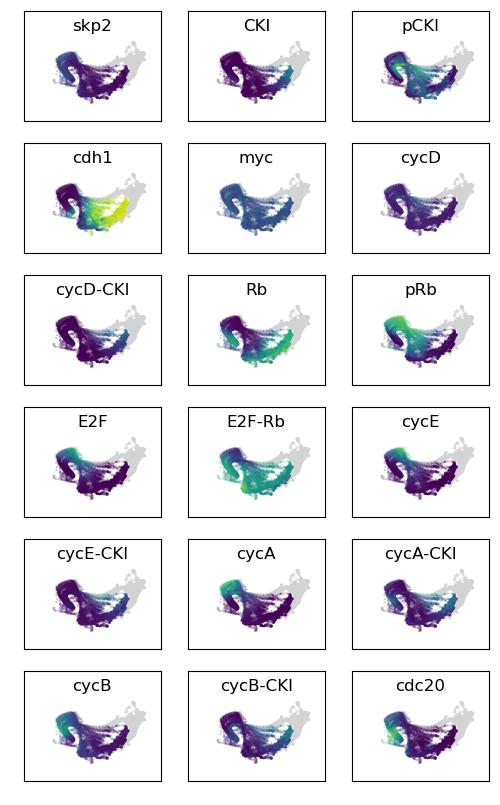

In [19]:
size = (6,10)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 2,
         'ytick.labelsize': 2}
plt.rcParams.update(params)
nrows = 6
ncols = 3

fig = plt.figure(figsize=size)

n=1
for prot in prot_names:
    ax = fig.add_subplot(nrows, ncols, n)
    plot_act(ax, fig, prot, tmp_s, tmp_l, short_bool=True)
    n+=1

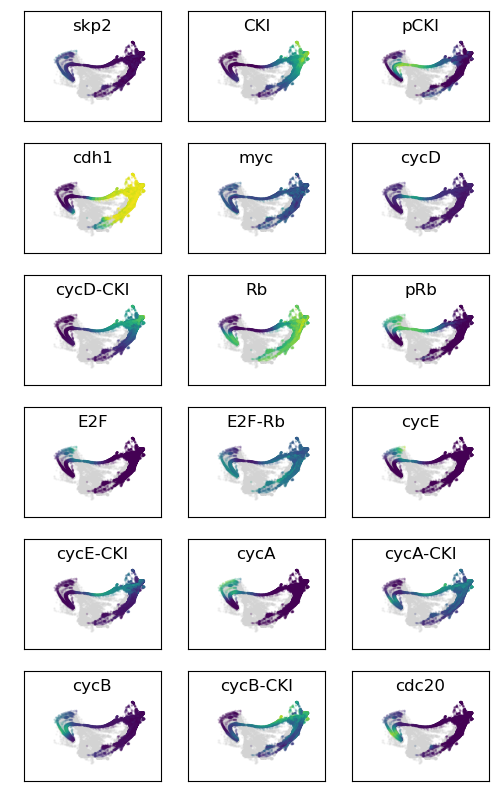

In [20]:
size = (6,10)
plt.rcParams.update(params)
nrows = 6
ncols = 3

fig = plt.figure(figsize=size)

n=1
for prot in prot_names:
    ax = fig.add_subplot(nrows, ncols, n)
    plot_act(ax, fig, prot, tmp_s, tmp_l, short_bool=False)
    n+=1

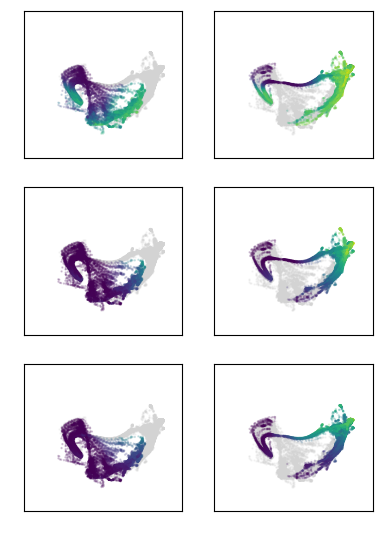

In [21]:
size = (4.5,6.5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 2,
         'ytick.labelsize': 2}
plt.rcParams.update(params)
nrows = 3
ncols = 2

fig, axes = plt.subplots(nrows, ncols, figsize=size, constrained_layout=False)

prots = ['Rb', 'CKI', 'cycD-CKI']

for r in range(nrows):
    prot = prots[r]
    for c in range(ncols):
        if c % 2 == 0:
            im = plot_act(axes[r][c], fig, prot, tmp_s, tmp_l, short_bool=True, fig_title=False)
        else:
            im = plot_act(axes[r][c], fig, prot, tmp_s, tmp_l, short_bool=False, fig_title=False)

# colorbar = fig.colorbar(im, ax=axes, shrink = 0.6)
# colorbar.ax.tick_params(labelsize=12)
# colorbar.set_ticks([0, 0.5, 1])

filepath = Path(SAVE_DIR, 'fig6B_relative_activity.png')
if SAVEFILES and (not filepath.exists() or OVERWRITE):
    plt.savefig(filepath, format='png', dpi=300)

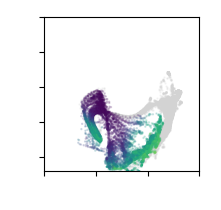

In [22]:
size = (2,2)
prot_to_plot = 'Rb'
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig, ax = plt.subplots(1,1, figsize=size)
xmin, xmax = -10, 20
ymin, ymax = -2, 20

x = np.array(tmp_s.UMAP1)
y = np.array(tmp_s.UMAP2)
H_s, xedges, yedges = np.histogram2d(y, x, bins=100, range= [[ymin,ymax], [xmin,xmax]], density=True)
x_centers = xedges[:-1] + np.diff(xedges)/2
y_centers = yedges[:-1] + np.diff(yedges)/2

ax.scatter(tmp_l.UMAP1, tmp_l.UMAP2, c='lightgray', s=0.5, alpha=0.2)
ax.scatter(tmp_s.UMAP1, tmp_s.UMAP2, c=tmp_s[prot_to_plot], s=0.5, alpha=0.2, vmin=0, vmax=1)

plt.xlim(xmin,xmax)
plt.ylim(ymin,ymax)
plt.xticks(np.arange(-10, 21, step=10))
plt.yticks(np.arange(0, 21, step=5))
plt.xticks(color='w')
plt.yticks(color='w')

filepath = Path(SAVE_DIR, f'fig6B_{prot_to_plot}_short.png')
if SAVEFILES and (not filepath.exists() or OVERWRITE):
    plt.savefig(filepath, format='png', dpi=300)


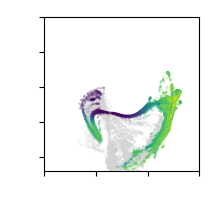

In [23]:
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
xmin, xmax = -10, 20
ymin, ymax = -2, 20

x = np.array(tmp_l.UMAP1)
y = np.array(tmp_l.UMAP2)
H_l, xedges, yedges = np.histogram2d(y, x, bins=100, range= [[ymin,ymax], [xmin,xmax]], density=True)
x_centers = xedges[:-1] + np.diff(xedges)/2
y_centers = yedges[:-1] + np.diff(yedges)/2

plt.scatter(tmp_s.UMAP1, tmp_s.UMAP2, c='lightgray', s=0.5, alpha=0.2)
plt.scatter(tmp_l.UMAP1, tmp_l.UMAP2, c=tmp_l[prot_to_plot], s=0.5, alpha=0.2, vmin=0, vmax=1)

plt.xlim(xmin,xmax)
plt.ylim(ymin,ymax)
plt.xticks(np.arange(-10, 21, step=10))
plt.yticks(np.arange(0, 21, step=5))
plt.xticks(color='w')
plt.yticks(color='w')

filepath = Path(SAVE_DIR, f'fig6B_{prot_to_plot}_long.png')
if SAVEFILES and (not filepath.exists() or OVERWRITE):
    plt.savefig(filepath, format='png', dpi=300)
    

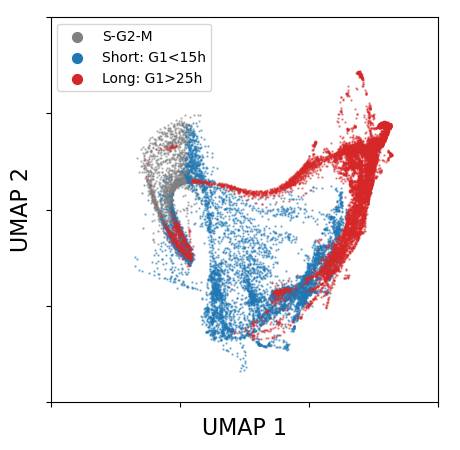

In [24]:
val = 0.0001
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
xmin, xmax = -10, 20
ymin, ymax = -5, 15


plt.scatter(tmp_l_SM.UMAP1, tmp_l_SM.UMAP2, c='gray', s=0.5, alpha=0.5)
plt.scatter(tmp_s_SM.UMAP1, tmp_s_SM.UMAP2, c='gray', s=0.5, alpha=0.5, label="S-G2-M")
plt.scatter(tmp_s_G1.UMAP1, tmp_s_G1.UMAP2, c='tab:blue', s=0.5, alpha=0.5, label="Short: G1<15h")
plt.scatter(tmp_l_G1.UMAP1, tmp_l_G1.UMAP2, c='tab:red', s=0.5, alpha=0.5, label="Long: G1>25h")

plt.xlim(xmin,xmax)
plt.ylim(ymin,ymax)
plt.xticks(np.arange(-10, 21, step=10))
plt.yticks(np.arange(-5, 16, step=5))

plt.xticks(color='w')
plt.yticks(color='w')

plt.xlabel('UMAP 1', labelpad=-10)
plt.ylabel('UMAP 2', labelpad=-15)

leg = plt.legend(markerscale=10)
for lh in leg.legend_handles: 
    lh.set_alpha(1)
    
filepath = Path(SAVE_DIR,'fig6A_uniqueG1.png')
if SAVEFILES and (not filepath.exists() or OVERWRITE):
    plt.savefig(filepath, format='png', dpi=300)


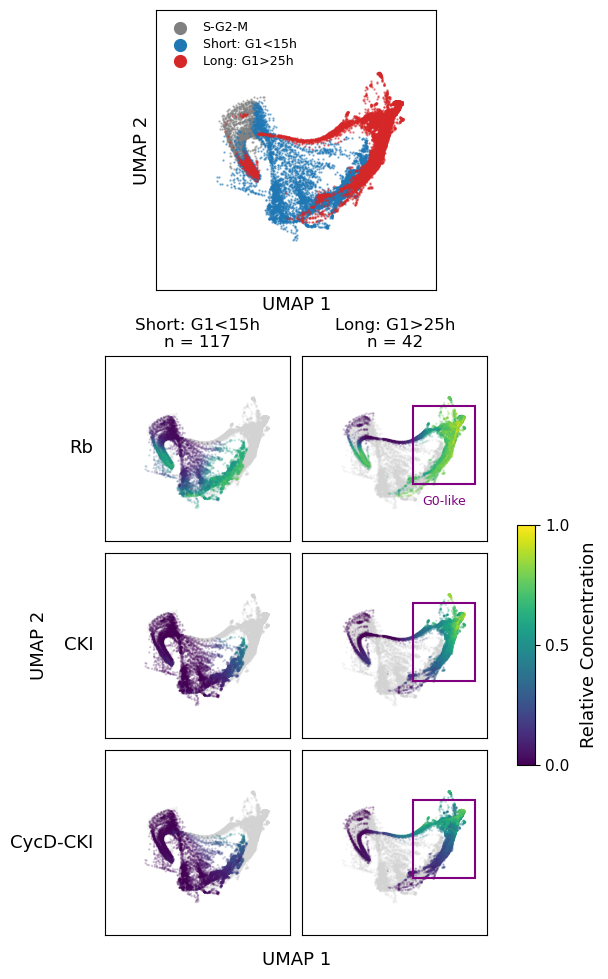

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

# ── Tunables ────────────────────────────────────────────────────────────────
N_SHORT, N_LONG = 117, 42
# shared, square-aspect range: x-span == y-span (= 30); YMAX gives top headroom for the legend
XMIN, XMAX = -10, 20
YMIN, YMAX = -8, 18
G0_X0, G0_Y0, G0_W, G0_H = 8, 0, 10, 11    # "G0-like" box (data coords) — moved up
ROW_FONTSZ = 13                              # row-label size (was 15)
UMAP2_X    = 1.2                            # left x (in) of the grid's "UMAP 2" label

W, H = 8.5, 11.0
def R(x, y, w, h):
    return [x / W, y / H, w / W, h / H]

plt.rcParams.update({'axes.edgecolor': 'black'})
fig = plt.figure(figsize=(W, H)); fig.patch.set_facecolor('white')

# Panel B grid geometry (defined first so Panel A can center on it)
PB, wgap, hgap = 1.85, 0.12, 0.12
gx, gb = 1.95, 1.15
grid_cx = gx + (2 * PB + wgap) / 2

# ── Panel A: square, same limits as B, legend upper-left ────────────────────
A_side = 2.8
A_x, A_y = grid_cx - A_side / 2, 7.6
axA = fig.add_axes(R(A_x, A_y, A_side, A_side))
axA.scatter(tmp_l_SM.UMAP1, tmp_l_SM.UMAP2, c='gray', s=0.5, alpha=0.5)
axA.scatter(tmp_s_SM.UMAP1, tmp_s_SM.UMAP2, c='gray', s=0.5, alpha=0.5, label='S-G2-M')
axA.scatter(tmp_s_G1.UMAP1, tmp_s_G1.UMAP2, c='tab:blue', s=0.5, alpha=0.5, label='Short: G1<15h')
axA.scatter(tmp_l_G1.UMAP1, tmp_l_G1.UMAP2, c='tab:red',  s=0.5, alpha=0.5, label='Long: G1>25h')
axA.set_xlim(XMIN, XMAX); axA.set_ylim(YMIN, YMAX)
axA.set_xticks([]); axA.set_yticks([])
axA.set_xlabel('UMAP 1', fontsize=13, labelpad=4)
axA.set_ylabel('UMAP 2', fontsize=13, labelpad=4)
legA = axA.legend(markerscale=12, fontsize=9, loc='upper left', frameon=False, labelspacing=0.3)
for lh in legA.legend_handles:
    lh.set_alpha(1)

# ── Panel B: 3 (Rb/CKI/CycD-CKI) x 2 (Short/Long) ───────────────────────────
data_prots = ['Rb', 'CKI', 'cycD-CKI']
row_labels = ['Rb', 'CKI', 'CycD-CKI']
col_titles = ['Short: G1<15h', 'Long: G1>25h']
col_counts = [f'n = {N_SHORT}', f'n = {N_LONG}']

def panelB(ax, prot, short):
    if short:
        ax.scatter(tmp_l.UMAP1, tmp_l.UMAP2, c='lightgray', s=0.5, alpha=0.2)
        ax.scatter(tmp_s.UMAP1, tmp_s.UMAP2, c=tmp_s[prot], s=0.5, alpha=0.2,
                   vmin=0, vmax=1, cmap='viridis')
    else:
        ax.scatter(tmp_s.UMAP1, tmp_s.UMAP2, c='lightgray', s=0.5, alpha=0.2)
        ax.scatter(tmp_l.UMAP1, tmp_l.UMAP2, c=tmp_l[prot], s=0.5, alpha=0.2,
                   vmin=0, vmax=1, cmap='viridis')
    ax.set_xlim(XMIN, XMAX); ax.set_ylim(YMIN, YMAX)
    ax.set_xticks([]); ax.set_yticks([])

top = gb + 3 * PB + 2 * hgap
for r in range(3):
    yb = top - (r + 1) * PB - r * hgap
    for c in range(2):
        ax = fig.add_axes(R(gx + c * (PB + wgap), yb, PB, PB))
        panelB(ax, data_prots[r], short=(c == 0))
        if c == 1:                                          # G0-like box, label BELOW
            ax.add_patch(Rectangle((G0_X0, G0_Y0), G0_W, G0_H,
                                   fill=False, edgecolor='purple', lw=1.5))
            if r == 0:
                ax.text(G0_X0 + G0_W / 2, G0_Y0 - 1.5, 'G0-like',
                        color='purple', fontsize=9, ha='center', va='top')
    fig.text((gx - 0.12) / W, (yb + PB / 2) / H, row_labels[r],
             fontsize=ROW_FONTSZ, va='center', ha='right')

for c in range(2):
    fig.text((gx + c * (PB + wgap) + PB / 2) / W, (top + 0.06) / H,
             f'{col_titles[c]}\n{col_counts[c]}', ha='center', va='bottom', fontsize=12)

fig.text(grid_cx / W, (gb - 0.3) / H, 'UMAP 1', ha='center', fontsize=13)
fig.text(UMAP2_X / W, (gb + (3 * PB + 2 * hgap) / 2) / H, 'UMAP 2',
         va='center', rotation=90, fontsize=13)

cax = fig.add_axes(R(gx + 2 * PB + wgap + 0.30, gb + 1.7, 0.18, 2.4))
sm = ScalarMappable(norm=Normalize(0, 1), cmap='viridis'); sm.set_array([])
cb = fig.colorbar(sm, cax=cax, ticks=[0, 0.5, 1])
cb.ax.tick_params(labelsize=11)
cb.set_label('Relative Concentration', fontsize=13, labelpad=8)

filepath = Path(SAVE_DIR, 'fig6_combined.png')
if SAVEFILES and (OVERWRITE or not filepath.exists()):
    fig.savefig(filepath, format='png', dpi=600)
plt.show()